# Lần chạy 2: kiểm tra và cải thiện phần khía cạnh

Lần chạy 1 (`aspect_model.ipynb`) cho thấy DistilBERT vượt rõ model cũ ở khen/chê, nhưng nhận khía cạnh chưa vượt từ khoá. Lần chạy này kiểm tra 4 giả thuyết, **chọn phương án trên tập dev và chỉ dùng tập test để báo cáo**:

| Phần | Giả thuyết | Cách kiểm tra |
|---|---|---|
| §2 | Thêm nhãn sẽ giúp nhận khía cạnh | Đường cong học: train với 25%, 50%, 75%, 100% số câu |
| §3 | Ngưỡng chọn trên dev có nhiều câu theo từ khoá làm model gán thừa | So ngưỡng chọn trên toàn bộ dev với chỉ phần dev ngẫu nhiên |
| §4 | Kết hợp từ khoá với transformer tốt hơn dùng riêng (đúng gợi ý của thầy) | Hợp, giao, xếp chồng (stacking), và đưa từ khoá vào đầu vào model |
| §5 | Sửa rò rỉ ở dev vẫn giữ được điểm mô hình theo cặp | Khởi tạo từ model khen/chê không học review của câu dev, so với khởi tạo từ DistilBERT gốc |

Nhãn do Claude gán, chưa có người kiểm tra độc lập.

In [1]:
import gc, json, os, re, sys, time
os.environ["KERAS_BACKEND"] = "torch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import warnings
warnings.filterwarnings("ignore")
from collections import Counter
from pathlib import Path

import keras, keras_hub, torch
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from IPython.display import display
from keras import layers as L, ops
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from tokenizers import Tokenizer

LABELS = Path("data/labels")
sys.path.insert(0, str(LABELS))
from aspect_keywords import detect as kw_detect

SMOKE = os.environ.get("DAT_SMOKE") == "1"
SEEDS = [0, 1] if SMOKE else [0, 1, 2]
EPOCHS_SENT, EPOCHS_ASP, EPOCHS_POL = (1, 1, 1) if SMOKE else (3, 6, 5)
BS, MAXLEN = 16, 128
ASPECTS = ["GFX", "AUD", "PLAY", "STORY", "PERF", "PRICE", "ONLINE", "DEV"]
ASPECT_WORD = dict(GFX="graphics", AUD="audio", PLAY="gameplay", STORY="story", PERF="performance", PRICE="price", ONLINE="online", DEV="developer")
ASPECT_VI = dict(GFX="Đồ hoạ", AUD="Âm thanh", PLAY="Gameplay", STORY="Cốt truyện", PERF="Hiệu năng, lỗi", PRICE="Giá, trả phí", ONLINE="Online, cộng đồng", DEV="Nhà phát triển")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

PROGRESS = LABELS / ("tien_do_smoke.txt" if SMOKE else "tien_do.txt")
PROGRESS.write_text("", encoding="utf-8")
TRACK = {"total": 1, "done": 0, "t0": time.time()}

def tien_do(msg):
    pct = 100 * TRACK["done"] / max(TRACK["total"], 1)
    el = time.time() - TRACK["t0"]
    eta = el / TRACK["done"] * (TRACK["total"] - TRACK["done"]) / 60 if TRACK["done"] else float("nan")
    line = f"[{time.strftime('%H:%M:%S')}] tổng {pct:5.1f}% | còn khoảng {eta:5.0f} phút | {msg}"
    print(line, flush=True)
    with open(PROGRESS, "a", encoding="utf-8") as f:
        f.write(line + "\n")

class ProgressCB(keras.callbacks.Callback):
    def __init__(self, name, every=50):
        super().__init__(); self.name, self.every, self.last = name, every, 0
    def on_train_batch_end(self, batch, logs=None):
        TRACK["done"] += 1
        if batch and batch % self.every == 0:
            tien_do(f"{self.name}: batch {batch}, loss {logs.get('loss', 0):.3f}")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ", "| Keras", keras.__version__, keras.backend.backend(), "| chạy thử nhanh:", SMOKE)

GPU: NVIDIA GeForce GTX 1650 | Keras 3.15.1 torch | chạy thử nhanh: False


In [2]:
df = pd.read_csv("data/steam_reviews_clean.csv")
df["text_clean"] = df.text_clean.astype(str)
y = df.label.values
idx = np.arange(len(df))
trA, teA = train_test_split(idx, test_size=.15, stratify=y, random_state=0)
trA, vaA = train_test_split(trA, test_size=.15 / .85, stratify=y[trA], random_state=0)
trB, teB = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=0).split(idx, groups=df.app_id))
trB, vaB = train_test_split(trB, test_size=.15, stratify=y[trB], random_state=0)
SPLITS = {"A": (trA, vaA, teA), "B": (trB, vaB, teB)}

def parse(a):
    return {} if a == "NONE" else {x.split(":")[0]: x.split(":")[1] for x in a.split("|")}
def load(key, lab):
    d = pd.read_csv(LABELS / key).merge(pd.read_csv(LABELS / lab, keep_default_na=False), on="sample_id")
    d["gold"] = d.aspects.map(parse)
    return d
S_TEST, S_EXTRA, S_TRAIN = load("sentences_key.csv", "sentences_labels.csv"), load("sentences_extra_key.csv", "sentences_extra_labels.csv"), load("train_sentences_key.csv", "train_sentences_labels.csv")
assert not set(S_TRAIN.review_id) & set(df.review_id.values[teA]), "rò rỉ: câu train thuộc review test"
R = pd.read_csv(LABELS / "reviews_key.csv").merge(pd.read_csv(LABELS / "reviews_labels.csv", keep_default_na=False), on="sample_id")
pos = dict(zip(df.review_id, range(len(df))))
R["i"] = R.review_id.map(pos)
R["y"] = y[R.i]
m4 = pd.read_csv(LABELS / "m4_preds.csv", dtype={"id": str}).set_index("id").p
tr_i, dv_i = next(GroupShuffleSplit(n_splits=1, test_size=.15, random_state=0).split(S_TRAIN, groups=S_TRAIN.review_id))
if SMOKE:
    trA, vaA, teA = trA[:320], vaA[:100], teA
    trB, vaB = trB[:320], vaB[:100]
    SPLITS = {"A": (trA, vaA, teA), "B": (trB, vaB, teB)}
    tr_i = tr_i[:160]
print("Review train/val/test A:", len(trA), len(vaA), len(teA), "| B:", len(trB), len(vaB), len(teB))
print("Câu train/dev/test/thêm:", len(tr_i), len(dv_i), len(S_TEST), len(S_EXTRA))
cnt = pd.DataFrame({n: Counter(a for g in d.gold for a in g) for n, d in [("train", S_TRAIN), ("test ngẫu nhiên", S_TEST), ("thêm", S_EXTRA)]}).loc[ASPECTS].rename(index=ASPECT_VI)
display(cnt)

Review train/val/test A: 6979 1496 1496 | B: 6813 1203 1955
Câu train/dev/test/thêm: 1265 235 500 110


,train,test ngẫu nhiên,thêm
Đồ hoạ,194,10,33
Âm thanh,142,3,31
Gameplay,432,110,37
Cốt truyện,136,17,30
"Hiệu năng, lỗi",166,47,12
"Giá, trả phí",171,24,17
"Online, cộng đồng",146,61,3
Nhà phát triển,141,52,7


In [3]:
tok = Tokenizer.from_pretrained("distilbert/distilbert-base-uncased")
CLS, SEP = tok.token_to_id("[CLS]"), tok.token_to_id("[SEP]")

def encode(texts, prefix=None):
    """prefix: từ khía cạnh đặt trước câu, dạng [CLS] khía cạnh [SEP] câu [SEP]."""
    ids = np.zeros((len(texts), MAXLEN), "int32"); mask = np.zeros((len(texts), MAXLEN), "int32")
    pre = [] if prefix is None else None
    enc = tok.encode_batch([str(t) for t in texts], add_special_tokens=False)
    pref = None if prefix is None else [tok.encode(p, add_special_tokens=False).ids for p in prefix]
    for i, e in enumerate(enc):
        head = [CLS] + ([] if pref is None else pref[i] + [SEP])
        room = MAXLEN - len(head) - 1
        t = e.ids if len(e.ids) <= room else e.ids[:room // 2] + e.ids[-(room - room // 2):]
        t = head + t + [SEP]
        ids[i, :len(t)] = t; mask[i, :len(t)] = 1
    return {"token_ids": ids, "padding_mask": mask}

class MaskMean(L.Layer):
    def call(self, x, m):
        m = ops.cast(m, x.dtype)[..., None]
        return ops.sum(x * m, 1) / (ops.sum(m, 1) + 1e-6)

def build(n_out, steps, lr=2e-5, init=None):
    b = keras_hub.models.DistilBertBackbone.from_preset("hf://distilbert/distilbert-base-uncased")
    if init is not None:
        b.set_weights(init)
    ids = keras.Input((MAXLEN,), dtype="int32", name="token_ids")
    mask = keras.Input((MAXLEN,), dtype="int32", name="padding_mask")
    x = L.Dropout(.2)(MaskMean()(b({"token_ids": ids, "padding_mask": mask}), mask))
    m = keras.Model([ids, mask], L.Dense(n_out, activation="sigmoid")(x))
    sch = keras.optimizers.schedules.CosineDecay(0., steps, warmup_target=lr, warmup_steps=max(1, int(.1 * steps)))
    m.compile(keras.optimizers.AdamW(sch, weight_decay=.01, clipnorm=1.), "binary_crossentropy")
    return m, b

def finetune(name, Xtr, ytr, Xdv, score, epochs, seed, n_out=1, lr=2e-5, init=None):
    """Train từng epoch, chấm trên dev bằng hàm score, giữ trọng số của epoch tốt nhất."""
    keras.utils.set_random_seed(seed)
    steps = epochs * (len(ytr) // BS + 1)
    m, b = build(n_out, steps, lr, init)
    best, hist, t0 = (-1, 0, None), [], time.time()
    for ep in range(epochs):
        h = m.fit(Xtr, ytr, batch_size=BS, epochs=1, verbose=0, callbacks=[ProgressCB(f"{name} epoch {ep + 1}/{epochs}")])
        a = score(m.predict(Xdv, batch_size=32, verbose=0))
        hist.append((ep + 1, round(h.history["loss"][0], 4), round(a, 4)))
        tien_do(f"{name} xong epoch {ep + 1}/{epochs}: điểm dev {a:.4f}")
        if a > best[0]:
            best = (a, ep + 1, [w.copy() for w in m.get_weights()])
    m.set_weights(best[2])
    return m, b, dict(name=name, best_epoch=best[1], dev=round(best[0], 4), seconds=round(time.time() - t0), hist=hist)

def free():
    gc.collect(); torch.cuda.empty_cache()

def predict_with(weights, n_out, X, batch_size=64):
    # dựng lại model từ trọng số đã lưu, dự đoán rồi giải phóng GPU
    m, b = build(n_out, 10)
    m.set_weights(weights)
    p = m.predict(X, batch_size=batch_size, verbose=0)
    del m, b; free()
    return p

# ước lượng tổng số batch để báo % và thời gian còn lại
TRACK["total"] = (sum(len(SPLITS[k][0]) // BS + 1 for k in "AB") * EPOCHS_SENT
                  + (len(tr_i) // BS + 1) * EPOCHS_ASP
                  + (sum(len(g) for g in S_TRAIN.iloc[tr_i].gold) // BS + 1) * EPOCHS_POL) * len(SEEDS)
TRACK["t0"] = time.time()
print("Tổng số batch dự kiến:", TRACK["total"])

Tổng số batch dự kiến: 10407


In [4]:
from sklearn.linear_model import LogisticRegression as LRC
from sklearn.model_selection import cross_val_predict
RUN = LABELS / "run2"; RUN.mkdir(exist_ok=True)
FRACS = [.25, .5, .75, 1.0]
SEEDS_CURVE = SEEDS[:2]
def Y_of(d):
    return np.array([[a in g for a in ASPECTS] for g in d.gold], "float32")
def prf(Y, H):
    Y, H = Y.astype(bool), H.astype(bool)
    tp, fp, fn = (Y & H).sum(0), (~Y & H).sum(0), (Y & ~H).sum(0)
    f = lambda t, p, n: 2 * t / max(2 * t + p + n, 1)
    per = {ASPECTS[i]: f(tp[i], fp[i], fn[i]) for i in range(Y.shape[1])}
    return dict(precision=tp.sum() / max(tp.sum() + fp.sum(), 1), recall=tp.sum() / max(tp.sum() + fn.sum(), 1), micro_f1=f(tp.sum(), fp.sum(), fn.sum()), macro_f1=np.mean(list(per.values()))), per
def tune_thr(Y, P):
    grid = np.arange(.1, .91, .05); t = []
    for j in range(Y.shape[1]):
        t.append(.5 if Y[:, j].sum() == 0 else max(grid, key=lambda g: (prf(Y[:, [j]], P[:, [j]] >= g)[0]["micro_f1"], -abs(g - .5))))
    return np.array(t)
DV = S_TRAIN.iloc[dv_i].reset_index(drop=True); TR = S_TRAIN.iloc[tr_i].reset_index(drop=True)
dv_rand = (DV.source == "random").values
Ytr, Ydv, Yte = Y_of(TR), Y_of(DV), Y_of(S_TEST)
KW = lambda d: np.array([[a in kw_detect(s) for a in ASPECTS] for s in d.sentence], "float32")
Kdv, Kte, Ktr = KW(DV), KW(S_TEST), KW(TR)
print("Câu dev:", len(DV), "| ngẫu nhiên:", int(dv_rand.sum()), "| số câu theo khía cạnh trong dev ngẫu nhiên:", dict(zip(ASPECTS, Ydv[dv_rand].sum(0).astype(int).tolist())))
Etr, Edv, Ete = encode(TR.sentence.values), encode(DV.sentence.values), encode(S_TEST.sentence.values)
take = lambda d, ix: {k: v[ix] for k, v in d.items()}
def kw_prefix(K):
    return [" ".join(ASPECT_WORD[a] for a, f in zip(ASPECTS, r) if f) or "none" for r in K]
Etr_k, Edv_k, Ete_k = encode(TR.sentence.values, kw_prefix(Ktr)), encode(DV.sentence.values, kw_prefix(Kdv)), encode(S_TEST.sentence.values, kw_prefix(Kte))
def pairs(d):
    rows = []
    for i, g in zip(d.index, d.gold):
        v = {x for x in g.values() if x in "KC"}
        for a, s in g.items():
            if s in "KC":
                rows.append((i, a, int(s == "K"), len(g) > 1, len(v) > 1))
    return pd.DataFrame(rows, columns=["i", "a", "y", "multi", "conflict"])
ALL_S = pd.concat([S_TEST, S_EXTRA], ignore_index=True)
Ptr, Pdv, Pte = pairs(TR), pairs(DV), pairs(ALL_S)
enc_pair = lambda d, P: encode(d.loc[P.i].sentence.values, [ASPECT_WORD[a] for a in P.a])
Etr_p, Edv_p, Ete_p = enc_pair(TR, Ptr), enc_pair(DV, Pdv), enc_pair(ALL_S, Pte)
ENC_S = encode(ALL_S.sentence.values)
# bỏ review của câu dev khỏi lúc train khen/chê để điểm dev của mô hình theo cặp không bị rò rỉ
dv_rev = set(DV.review_id)
trA_clean = np.array([i for i in trA if df.review_id.values[i] not in dv_rev])
ENC = encode(df.text_clean.values)
bt = lambda n: n // BS + 1
TRACK["total"] = (sum(bt(int(len(TR) * f)) * EPOCHS_ASP * len(SEEDS_CURVE) for f in FRACS[:-1]) + bt(len(TR)) * EPOCHS_ASP * len(SEEDS) * 2
                  + bt(len(trA_clean)) * EPOCHS_SENT + bt(len(Ptr)) * EPOCHS_POL * len(SEEDS) * 2)
TRACK["done"] = 0; TRACK["t0"] = time.time()
print("Review bỏ ra khỏi train khen/chê:", len(trA) - len(trA_clean), "| Tổng batch:", TRACK["total"])

Câu dev: 235 | ngẫu nhiên: 138 | số câu theo khía cạnh trong dev ngẫu nhiên: {'GFX': 5, 'AUD': 1, 'PLAY': 46, 'STORY': 6, 'PERF': 18, 'PRICE': 9, 'ONLINE': 12, 'DEV': 16}


Review bỏ ra khỏi train khen/chê: 168 | Tổng batch: 7728


## 2. Đường cong học: thêm nhãn có giúp không?

Train nhận khía cạnh với 25%, 50%, 75% và 100% số câu train. Nếu điểm còn tăng rõ ở đoạn cuối thì thêm nhãn đáng làm; nếu đã phẳng thì không. Ngưỡng chọn trên phần dev ngẫu nhiên.

[16:18:18] tổng   0.0% | còn khoảng   nan phút | BẮT ĐẦU Đường cong 25%, seed 0


[16:18:32] tổng   0.3% | còn khoảng    88 phút | Đường cong 25%, seed 0 xong epoch 1/6: điểm dev 0.0000


[16:18:42] tổng   0.5% | còn khoảng    77 phút | Đường cong 25%, seed 0 xong epoch 2/6: điểm dev 0.0000


[16:18:52] tổng   0.8% | còn khoảng    73 phút | Đường cong 25%, seed 0 xong epoch 3/6: điểm dev 0.1322


[16:19:03] tổng   1.0% | còn khoảng    71 phút | Đường cong 25%, seed 0 xong epoch 4/6: điểm dev 0.2047


[16:19:13] tổng   1.3% | còn khoảng    69 phút | Đường cong 25%, seed 0 xong epoch 5/6: điểm dev 0.2500


... (94 outputs left out)

[16:41:11] tổng  37.3% | còn khoảng    39 phút | Đường cong 100%, seed 2 xong epoch 6/6: điểm dev 0.6280


[16:41:17] tổng  37.3% | còn khoảng    39 phút | XONG đường cong 100%, seed 2: F1 test 0.634


,tỉ_lệ,số_câu,seed,dev_ngẫu_nhiên,test,precision,recall
0,0.25,316,0,0.507,0.433,0.354,0.556
1,0.25,316,1,0.516,0.452,0.380,0.559
2,0.50,632,0,0.658,0.565,0.543,0.590
3,0.50,632,1,0.624,0.568,0.528,0.614
4,0.75,948,0,0.689,0.605,0.543,0.682
5,0.75,948,1,0.647,0.559,0.486,0.657
6,1.00,1265,0,0.686,0.610,0.530,0.719
7,1.00,1265,1,0.697,0.607,0.523,0.722
8,1.00,1265,2,0.675,0.634,0.597,0.676


,dev_ngẫu_nhiên,test
số_câu,,
316,0.512,0.442
632,0.641,0.566
948,0.668,0.582
1265,0.686,0.617


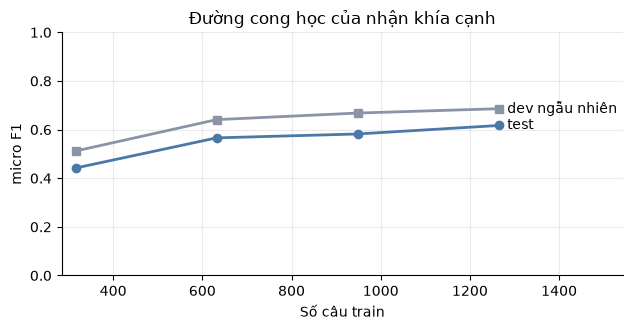

In [5]:
def run_det(name, Xtr, Y, Xdv, Xte, seed):
    tien_do(f"BẮT ĐẦU {name}")
    m, b, log = finetune(name, Xtr, Y, Xdv, lambda p: prf(Ydv[dv_rand], p[dv_rand] >= .5)[0]["micro_f1"], EPOCHS_ASP, seed, n_out=8, lr=3e-5)
    pd_, pt = m.predict(Xdv, batch_size=32, verbose=0), m.predict(Xte, batch_size=32, verbose=0)
    del m, b; free()
    return pd_, pt, log
CURVE, FULL, LOGS = [], {}, []
for f in FRACS:
    n = int(len(TR) * f)
    for s in (SEEDS if f == 1 else SEEDS_CURVE):
        ix = np.random.default_rng(100 + s).permutation(len(TR))[:n] if f < 1 else np.arange(len(TR))
        pd_, pt, log = run_det(f"Đường cong {int(f * 100)}%, seed {s}", take(Etr, ix), Ytr[ix], Edv, Ete, s)
        LOGS.append(log)
        thr = tune_thr(Ydv[dv_rand], pd_[dv_rand])
        r_dev, r_te = prf(Ydv[dv_rand], pd_[dv_rand] >= thr)[0], prf(Yte, pt >= thr)[0]
        CURVE.append(dict(tỉ_lệ=f, số_câu=n, seed=s, dev_ngẫu_nhiên=round(r_dev["micro_f1"], 3), test=round(r_te["micro_f1"], 3), precision=round(r_te["precision"], 3), recall=round(r_te["recall"], 3)))
        tien_do(f"XONG đường cong {int(f * 100)}%, seed {s}: F1 test {CURVE[-1]['test']}")
        if f == 1:
            FULL[s] = (pd_, pt)
CV = pd.DataFrame(CURVE); display(CV)
CV.to_csv(RUN / "duong_cong_hoc.csv", index=False)
g = CV.groupby("số_câu")[["dev_ngẫu_nhiên", "test"]].mean().round(3); display(g)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(g.index, g["test"], marker="o", color="#4C78A8", lw=2); ax.plot(g.index, g["dev_ngẫu_nhiên"], marker="s", color="#8A94A6", lw=2)
ax.annotate("test", (g.index[-1], g["test"].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center"); ax.annotate("dev ngẫu nhiên", (g.index[-1], g["dev_ngẫu_nhiên"].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center")
ax.set(xlabel="Số câu train", ylabel="micro F1", title="Đường cong học của nhận khía cạnh", ylim=(0, 1), xlim=(g.index[0] * .9, g.index[-1] * 1.22)); plt.tight_layout(); plt.show()

**Nhận xét** — Điểm còn tăng ở đoạn cuối: F1 test trung bình 0,443 (316 câu), 0,567 (632 câu), 0,582 (948 câu), 0,617 (1.265 câu). Mức tăng từ 948 lên 1.265 câu là 0,035, lớn hơn độ lệch giữa seed (khoảng 0,012) nhưng các điểm trung gian chỉ có 2 seed. Đường cong chưa phẳng nên thêm nhãn có tiềm năng; phần này được làm ở `aspect_model_run3.ipynb`.

## 3. Chọn ngưỡng theo phần dev nào?

Cùng các model 100% ở §2, so hai cách chọn ngưỡng: trên toàn bộ dev (nhiều câu chọn theo từ khoá) và chỉ trên phần dev ngẫu nhiên (cùng phân phối với tập test).

In [6]:
rows = []
for s, (pd_, pt) in FULL.items():
    for n, m_ in [("Toàn bộ dev", np.ones(len(DV), bool)), ("Dev ngẫu nhiên", dv_rand)]:
        r = prf(Yte, pt >= tune_thr(Ydv[m_], pd_[m_]))[0]
        rows.append(dict(cách_chọn=n, seed=s, **{k: round(v, 3) for k, v in r.items()}))
T = pd.DataFrame(rows); display(T.groupby("cách_chọn")[["precision", "recall", "micro_f1", "macro_f1"]].mean().round(3))
T.to_csv(RUN / "chon_nguong.csv", index=False)

,precision,recall,micro_f1,macro_f1
cách_chọn,,,,
Dev ngẫu nhiên,0.550,0.706,0.617,0.672
Toàn bộ dev,0.524,0.735,0.611,0.655


**Nhận xét** — Chọn ngưỡng trên dev ngẫu nhiên cho micro F1 0,617, so với 0,611 khi dùng toàn bộ dev; precision tăng từ 0,524 lên 0,550, recall giảm từ 0,735 xuống 0,706. Chênh lệch nằm trong dao động giữa seed, nên giả thuyết về ngưỡng chỉ giải thích được một phần nhỏ. Các phần sau vẫn dùng dev ngẫu nhiên vì nó cùng phân phối với tập test.

## 4. Kết hợp từ khoá với transformer

Đây là phần đi đúng gợi ý của thầy. Các cách thử:

- **Hợp:** từ khoá hoặc model nói có thì tính là có.
- **Giao:** cả hai cùng nói có.
- **Xếp chồng:** với từng khía cạnh, một LR nhỏ học cách cân xác suất của model với cờ từ khoá.
- **Từ khoá trong đầu vào:** đưa các khía cạnh từ khoá tìm được vào trước câu, `[CLS] graphics price [SEP] câu [SEP]`, để transformer tự quyết có tin từ khoá hay không. Train lại từ đầu.

Phương án được chọn theo micro F1 trên dev ngẫu nhiên. Riêng xếp chồng dùng dự đoán chéo 5 phần trên dev để điểm dev không bị lạc quan.

In [7]:
KWIN = {}
for s in SEEDS:
    pd_, pt, log = run_det(f"Từ khoá trong đầu vào, seed {s}", Etr_k, Ytr, Edv_k, Ete_k, s); LOGS.append(log)
    KWIN[s] = (pd_, pt)
    tien_do(f"XONG từ khoá trong đầu vào, seed {s}")
def logit(p):
    p = p.clip(1e-4, 1 - 1e-4); return np.log(p / (1 - p))
def stack(pd_, pt):
    Pdv_, Pte_ = np.zeros_like(pd_), np.zeros_like(pt)
    for j in range(8):
        Xd, Xt = np.column_stack([logit(pd_[:, j]), Kdv[:, j]]), np.column_stack([logit(pt[:, j]), Kte[:, j]])
        c = LRC(C=1, max_iter=1000)
        Pdv_[:, j] = cross_val_predict(c, Xd, Ydv[:, j], cv=5, method="predict_proba")[:, 1]
        Pte_[:, j] = c.fit(Xd, Ydv[:, j]).predict_proba(Xt)[:, 1]
    return Pdv_, Pte_
rows, H_BY = [], {}
def add(name, s, Hd, Ht):
    rd, rt = prf(Ydv[dv_rand], Hd[dv_rand])[0], prf(Yte, Ht)[0]
    rows.append(dict(phương_án=name, seed=s, dev=round(rd["micro_f1"], 3), test=round(rt["micro_f1"], 3), precision=round(rt["precision"], 3), recall=round(rt["recall"], 3), macro_f1=round(rt["macro_f1"], 3)))
    H_BY.setdefault(name, {})[s] = Ht
add("Từ khoá", SEEDS[0], Kdv.astype(bool), Kte.astype(bool))
for s, (pd_, pt) in FULL.items():
    thr = tune_thr(Ydv[dv_rand], pd_[dv_rand]); Hd, Ht = pd_ >= thr, pt >= thr
    add("DistilBERT", s, Hd, Ht)
    add("Hợp", s, Hd | Kdv.astype(bool), Ht | Kte.astype(bool))
    add("Giao", s, Hd & Kdv.astype(bool), Ht & Kte.astype(bool))
    a, b_ = stack(pd_, pt); th = tune_thr(Ydv[dv_rand], a[dv_rand])
    add("Xếp chồng", s, a >= th, b_ >= th)
for s, (pd_, pt) in KWIN.items():
    thr = tune_thr(Ydv[dv_rand], pd_[dv_rand])
    add("Từ khoá trong đầu vào", s, pd_ >= thr, pt >= thr)
HY = pd.DataFrame(rows); HY.to_csv(RUN / "ket_hop_tu_khoa.csv", index=False)
HM = HY.groupby("phương_án")[["dev", "test", "precision", "recall", "macro_f1"]].mean().round(3).sort_values("dev", ascending=False); display(HM)
print("Độ lệch F1 test giữa seed:", HY.groupby("phương_án").test.std(ddof=0).round(3).to_dict())
BEST_DET = HM.index[0]; print("Phương án được chọn trên dev:", BEST_DET)
per = pd.DataFrame({n: {ASPECT_VI[a]: round(np.mean([prf(Yte, h)[1][a] for h in H_BY[n].values()]), 2) for a in ASPECTS} for n in dict.fromkeys(["Từ khoá", "DistilBERT", BEST_DET])})
per.insert(0, "số câu thật", [int(Yte[:, j].sum()) for j in range(8)]); display(per); per.to_csv(RUN / "f1_theo_khia_canh.csv")

[16:41:17] tổng  37.3% | còn khoảng    39 phút | BẮT ĐẦU Từ khoá trong đầu vào, seed 0


[16:41:41] tổng  37.9% | còn khoảng    38 phút | Từ khoá trong đầu vào, seed 0 epoch 1/6: batch 50, loss 0.468


[16:41:54] tổng  38.3% | còn khoảng    38 phút | Từ khoá trong đầu vào, seed 0 xong epoch 1/6: điểm dev 0.3239


[16:42:16] tổng  39.0% | còn khoảng    38 phút | Từ khoá trong đầu vào, seed 0 epoch 2/6: batch 50, loss 0.208


[16:42:30] tổng  39.3% | còn khoảng    37 phút | Từ khoá trong đầu vào, seed 0 xong epoch 2/6: điểm dev 0.5652


[16:42:51] tổng  40.0% | còn khoảng    37 phút | Từ khoá trong đầu vào, seed 0 epoch 3/6: batch 50, loss 0.139


... (35 outputs left out)

[16:52:17] tổng  55.9% | còn khoảng    27 phút | XONG từ khoá trong đầu vào, seed 2


,dev,test,precision,recall,macro_f1
phương_án,,,,,
Từ khoá trong đầu vào,0.702,0.691,0.687,0.703,0.716
Xếp chồng,0.693,0.628,0.527,0.778,0.671
DistilBERT,0.686,0.617,0.550,0.706,0.672
Hợp,0.675,0.657,0.549,0.820,0.671
Giao,0.511,0.578,0.850,0.438,0.646
Từ khoá,0.511,0.640,0.762,0.552,0.663


Độ lệch F1 test giữa seed: {'DistilBERT': 0.012, 'Giao': 0.0, 'Hợp': 0.013, 'Từ khoá': 0.0, 'Từ khoá trong đầu vào': 0.003, 'Xếp chồng': 0.003}
Phương án được chọn trên dev: Từ khoá trong đầu vào


,số câu thật,Từ khoá,DistilBERT,Từ khoá trong đầu vào
Đồ hoạ,10,0.80,0.53,0.74
Âm thanh,3,0.57,1.00,0.87
Gameplay,110,0.50,0.60,0.69
Cốt truyện,17,0.72,0.79,0.74
"Hiệu năng, lỗi",47,0.72,0.67,0.77
"Giá, trả phí",24,0.62,0.58,0.62
"Online, cộng đồng",61,0.74,0.64,0.72
Nhà phát triển,52,0.63,0.55,0.58


**Nhận xét** — Đưa từ khoá vào đầu vào transformer là phương án tốt nhất trên dev (0,702) và cũng tốt nhất trên test (micro F1 0,691, độ lệch giữa seed 0,003), cao hơn DistilBERT riêng (0,617) và từ khoá riêng (0,640). Hai cách ghép ở đầu ra kém hơn: hợp đạt 0,657 và xếp chồng 0,628. Cách này cân bằng precision (0,687) và recall (0,703). Cần lưu ý từ khoá đạt 0,640 trên tập test nhưng chỉ 0,511 trên dev ngẫu nhiên, vì danh sách từ khoá được viết sau khi đã đọc tập test. Do đó so sánh trên tập test đang có lợi cho từ khoá và cho cả phương án dùng từ khoá; `aspect_model_run3.ipynb` chấm lại trên một tập test mới gán sau khi đã khoá danh sách từ khoá.

## 5. Khen/chê theo cặp: sửa rò rỉ ở dev

Train lại model khen/chê trên nhãn Steam nhưng **bỏ các review chứa câu dev**, rồi dùng làm trọng số khởi tạo. Điểm dev giờ mới phản ánh đúng và dùng để chọn epoch được. So thêm với khởi tạo từ DistilBERT gốc để xem việc học trước nhãn Steam có đáng không.

In [8]:
tien_do("BẮT ĐẦU khen/chê nhãn Steam, bỏ review của câu dev")
m, b, log = finetune("Khen/chê sạch", take(ENC, trA_clean), y[trA_clean].astype("float32"), take(ENC, vaA), lambda p: roc_auc_score(y[vaA], p.ravel()), EPOCHS_SENT, SEEDS[0]); LOGS.append(log)
SENT_S = m.predict(ENC_S, batch_size=32, verbose=0).ravel()
SENT_T = m.predict(take(ENC, teA), batch_size=32, verbose=0).ravel()
print("AUC test A:", round(roc_auc_score(y[teA], SENT_T), 4))
INIT = [w.copy() for w in b.get_weights()]
del m, b; free()
POL, POLW, DEVLOG = {"Khởi tạo nhãn Steam, đã sửa rò rỉ": [], "Khởi tạo DistilBERT gốc": []}, {}, []
for name, init in [("Khởi tạo nhãn Steam, đã sửa rò rỉ", INIT), ("Khởi tạo DistilBERT gốc", None)]:
    for s in SEEDS:
        tien_do(f"BẮT ĐẦU theo cặp: {name}, seed {s}")
        m, b, log = finetune(f"Theo cặp ({name}), seed {s}", Etr_p, Ptr.y.values.astype("float32"), Edv_p, lambda p: roc_auc_score(Pdv.y, p.ravel()), EPOCHS_POL, s, init=init); LOGS.append(log)
        POL[name].append(m.predict(Ete_p, batch_size=32, verbose=0).ravel()); DEVLOG.append(dict(cách=name, seed=s, dev=log["dev"], epoch=log["best_epoch"]))
        POLW[(name, s)] = [w.copy() for w in m.get_weights()]
        del m, b; free()
display(pd.DataFrame(DEVLOG))
M4_S = m4.loc[ALL_S.sample_id].values
subs = [("Tất cả", np.ones(len(Pte), bool)), ("Câu 1 khía cạnh", ~Pte.multi.values), ("Nhiều khía cạnh, cùng cảm xúc", (Pte.multi & ~Pte.conflict).values), ("Nhiều khía cạnh, trái cảm xúc", Pte.conflict.values), ("Thật sự là Khen", (Pte.y == 1).values), ("Thật sự là Chê", (Pte.y == 0).values)]
rows = []
for n, f in subs:
    yy = Pte.y.values[f]; acc = lambda p: accuracy_score(yy, p[f] >= .5)
    row = {"nhóm": n, "số cặp": int(f.sum()), "M4 cả câu": round(acc(M4_S[Pte.i.values]), 3), "DistilBERT cả câu": round(acc(SENT_S[Pte.i.values]), 3)}
    for k, v in POL.items():
        row[k] = round(np.mean([acc(p) for p in v]), 3)
    rows.append(row)
PT = pd.DataFrame(rows).set_index("nhóm"); display(PT); PT.to_csv(RUN / "khen_che_theo_cap.csv")
BEST_POL = max(POL, key=lambda k: np.mean([d["dev"] for d in DEVLOG if d["cách"] == k])); print("Chọn trên dev:", BEST_POL)
AUC = {"M4": roc_auc_score(Pte.y, M4_S[Pte.i.values]), "DistilBERT cả câu": roc_auc_score(Pte.y, SENT_S[Pte.i.values]), **{k: np.mean([roc_auc_score(Pte.y, p) for p in v]) for k, v in POL.items()}}
print({k: round(float(v), 3) for k, v in AUC.items()})

[16:52:18] tổng  55.9% | còn khoảng    27 phút | BẮT ĐẦU khen/chê nhãn Steam, bỏ review của câu dev


[16:52:41] tổng  56.6% | còn khoảng    26 phút | Khen/chê sạch epoch 1/3: batch 50, loss 0.699


[16:53:03] tổng  57.2% | còn khoảng    26 phút | Khen/chê sạch epoch 1/3: batch 100, loss 0.651


[16:53:24] tổng  57.9% | còn khoảng    26 phút | Khen/chê sạch epoch 1/3: batch 150, loss 0.599


[16:53:46] tổng  58.5% | còn khoảng    25 phút | Khen/chê sạch epoch 1/3: batch 200, loss 0.551


[16:54:07] tổng  59.1% | còn khoảng    25 phút | Khen/chê sạch epoch 1/3: batch 250, loss 0.527


... (88 outputs left out)

[17:18:40] tổng 100.0% | còn khoảng     0 phút | Theo cặp (Khởi tạo DistilBERT gốc), seed 2 xong epoch 5/5: điểm dev 0.9892


,cách,seed,dev,epoch
0,"Khởi tạo nhãn Steam, đã sửa rò rỉ",0,0.9920,3
1,"Khởi tạo nhãn Steam, đã sửa rò rỉ",1,0.9927,3
2,"Khởi tạo nhãn Steam, đã sửa rò rỉ",2,0.9939,3
3,Khởi tạo DistilBERT gốc,0,0.9847,5
4,Khởi tạo DistilBERT gốc,1,0.9867,3
5,Khởi tạo DistilBERT gốc,2,0.9909,3


,số cặp,M4 cả câu,DistilBERT cả câu,"Khởi tạo nhãn Steam, đã sửa rò rỉ",Khởi tạo DistilBERT gốc
nhóm,,,,,
Tất cả,445,0.753,0.874,0.897,0.881
Câu 1 khía cạnh,264,0.727,0.875,0.898,0.886
"Nhiều khía cạnh, cùng cảm xúc",153,0.837,0.935,0.956,0.935
"Nhiều khía cạnh, trái cảm xúc",28,0.536,0.536,0.560,0.536
Thật sự là Khen,148,0.919,0.905,0.867,0.838
Thật sự là Chê,297,0.670,0.859,0.911,0.902


Chọn trên dev: Khởi tạo nhãn Steam, đã sửa rò rỉ
{'M4': 0.903, 'DistilBERT cả câu': 0.941, 'Khởi tạo nhãn Steam, đã sửa rò rỉ': 0.961, 'Khởi tạo DistilBERT gốc': 0.949}


**Nhận xét** — Khởi tạo từ model khen/chê đã bỏ review của câu dev đạt độ chính xác 0,897 và ROC-AUC 0,961, cao hơn khởi tạo từ DistilBERT gốc (0,881 và 0,949). Giả thuyết rò rỉ không được xác nhận: cả hai cách vẫn có điểm dev 0,985–0,994, kể cả khi không dùng trọng số đã học nhãn Steam. Điểm dev cao nhiều khả năng do tập dev dễ hơn tập test, trong đó có các câu chọn theo từ khoá, nên việc chọn epoch trên tập này ít phân biệt. Nhóm câu trái cảm xúc vẫn chưa cải thiện (0,560, n=28).

## 6. Cả đường ống với phương án được chọn

Chấm trên 500 câu ngẫu nhiên, đúng khi đúng cả khía cạnh lẫn cảm xúc, trung bình các seed cho phương án có học.

In [9]:
TEST_PAIR = encode(np.repeat(S_TEST.sentence.values, 8), [ASPECT_WORD[a] for a in ASPECTS] * len(S_TEST))
Pp = {s: predict_with(POLW[(BEST_POL, s)], 1, TEST_PAIR).reshape(len(S_TEST), 8) for s in SEEDS}
def pipe_f1(H, pol):
    tp = fp = fn = 0
    for i, g in enumerate(S_TEST.gold):
        gold = {(a, v) for a, v in g.items() if v in "KC"}; skip = {a for a, v in g.items() if v not in "KC"}
        pred = {(ASPECTS[j], "K" if pol(i, j) >= .5 else "C") for j in range(8) if H[i, j] and ASPECTS[j] not in skip}
        tp += len(gold & pred); fp += len(pred - gold); fn += len(gold - pred)
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(đúng=tp, thừa=fp, thiếu=fn, precision=round(p, 3), recall=round(r, 3), F1=round(2 * p * r / max(p + r, 1e-9), 3))
Kb = Kte.astype(bool)
mean_rows = lambda L: pd.DataFrame(L).mean().round(3).to_dict()
det_h = lambda s: H_BY[BEST_DET].get(s, H_BY[BEST_DET][SEEDS[0]])
rows = {"Cũ: từ khoá + M4": pipe_f1(Kb, lambda i, j: M4_S[i]), "A: từ khoá + DistilBERT cả câu": pipe_f1(Kb, lambda i, j: SENT_S[i]),
        "Từ khoá + DistilBERT theo cặp": mean_rows([pipe_f1(Kb, lambda i, j, s=s: Pp[s][i, j]) for s in SEEDS]),
        f"{BEST_DET} + DistilBERT theo cặp": mean_rows([pipe_f1(det_h(s), lambda i, j, s=s: Pp[s][i, j]) for s in SEEDS])}
PIPE = pd.DataFrame(rows).T; display(PIPE); PIPE.to_csv(RUN / "ca_duong_ong.csv")
np.savez(RUN / "du_doan.npz", **{f"det_{n}_{s}": h for n, d in H_BY.items() for s, h in d.items()}, sent_s=SENT_S, sent_t=SENT_T, **{f"pol_{s}": Pp[s] for s in SEEDS})
json.dump(dict(BEST_DET=BEST_DET, BEST_POL=BEST_POL), open(RUN / "chon.json", "w", encoding="utf-8"), ensure_ascii=False)
json.dump(LOGS, open(RUN / "nhat_ky_train.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
TRACK["done"] = TRACK["total"]; tien_do("HOÀN TẤT lần chạy 2")

,đúng,thừa,thiếu,precision,recall,F1
Cũ: từ khoá + M4,126.000,94.000,164.000,0.573,0.434,0.494
A: từ khoá + DistilBERT cả câu,142.000,78.000,148.000,0.645,0.490,0.557
Từ khoá + DistilBERT theo cặp,146.667,73.333,143.333,0.667,0.506,0.575
Từ khoá trong đầu vào + DistilBERT theo cặp,183.333,129.000,106.667,0.593,0.632,0.609


[17:20:24] tổng 100.0% | còn khoảng     0 phút | HOÀN TẤT lần chạy 2


**Nhận xét** — Ghép từ khoá trong đầu vào với mô hình theo cặp cho F1 0,609, so với 0,494 của bản cũ và 0,575 khi nhận khía cạnh chỉ bằng từ khoá. Mức tăng đến từ recall (0,632 so với 0,434), với precision gần như giữ nguyên (0,593 so với 0,573).

## 7. Tổng kết

- **Kết hợp từ khoá với transformer có hiệu quả** khi đưa từ khoá vào đầu vào: nhận khía cạnh F1 0,691, cao hơn dùng riêng từng phần.
- **Đường cong học chưa phẳng**, nên thêm nhãn có tiềm năng.
- **Ngưỡng và rò rỉ** không phải nguyên nhân chính của các vấn đề đã nêu ở lần chạy 1.
- **Từ khoá có lợi thế trên tập test cũ** vì được viết sau khi đọc tập này; cần tập test mới để so sánh công bằng.
- **Kế tiếp:** `aspect_model_run3.ipynb` gán thêm nhãn, chấm trên tập test mới.